In [1]:
from pathlib import Path
import sys
import warnings

warnings.simplefilter("ignore")

repo_root = Path.cwd() if (Path.cwd() / "course_tools").is_dir() else Path.cwd().parent
for _p in (repo_root, repo_root / "course_tools" / "src"):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import numpy as np
import torch
import bayesian_stats_course_tools
from sbi_lecture import abc, density_estimation, interactive_widgets as iw, neural_sbi, plinko, precompute, validation

# Load precomputed Galton-board simulation bank, checkpoints, and trained NPE/NLE/NRE models (<1s, offline)
bundle = precompute.load_lecture_bundle()

In [2]:
title = "# Simulation-Based Inference"
# Print title and setup TeX defs for both KaTeX and MathJax (matches Weeks 1–9)
bayesian_stats_course_tools.misc.display_markdown_and_setup_tex(title)

import matplotlib.style
matplotlib.style.use("bayesian_stats_course_tools.light")

# Simulation-Based Inference

<!-- Define LaTeX macros -->
$\def\E{\operatorname{E}}$
$\def\Var{\operatorname{Var}}$
$\def\Cov{\operatorname{Cov}}$
$\def\dd{\mathrm{d}}$
$\def\ee{\mathrm{e}}$
$\def\Norm{\mathcal{N}}$
$\def\Uniform{\mathcal{U}}$
$\def\GP{\mathcal{GP}}$

<!-- MathJax needs them to be defined again for the non-inline environment -->
$$\def\E{\operatorname{E}}$$
$$\def\Var{\operatorname{Var}}$$
$$\def\Cov{\operatorname{Cov}}$$
$$\def\dd{\mathrm{d}}$$
$$\def\ee{\mathrm{e}}$$
$$\def\Norm{\mathcal{N}}$$
$$\def\Uniform{\mathcal{U}}$$
$$\def\GP{\mathcal{GP}}$$


**ETH Zürich · Bayesian Statistics and Data Analysis · HS2026 (Week 10)**

> **Central question for today:** *If we can simulate an experiment faithfully on a computer, can we infer the hidden parameters of that experiment from observed data alone?*


2 min | Pose the opening question without answering it yet. Remind students that Weeks 5-9 relied on evaluating L(theta) = p(x_obs | theta); today asks what happens when we only have forward simulation code.

## Scientific Inference Is an Inverse Problem

$$\underbrace{\theta \;\xrightarrow{\;\text{Forward simulator}\;}\; x \sim p(x\mid\theta)}_{\textbf{Forward prediction}} \qquad\Longleftrightarrow\qquad \underbrace{x_{\mathrm{obs}} \;\xrightarrow{\;\text{Bayesian inference}\;}\; p(\theta\mid x_{\mathrm{obs}})}_{\textbf{Bayesian inverse problem}}$$

- **Forward prediction ($\theta \to x$):** specify physical parameters $\theta$ and execute the mechanistic model to generate synthetic data $x$.
- **Parameter inference ($x_{\mathrm{obs}} \to \theta$):** given a single noisy experimental realization $x_{\mathrm{obs}}$, determine the full posterior distribution over all parameter configurations $\theta$ compatible with $x_{\mathrm{obs}}$.

In [3]:
iw.demo('w01_forward_inverse')

<InteractiveDemo w01_forward_inverse: W01: Forward Prediction vs Bayesian Inverse Problem>

3 min | Demonstrate W01 in Forward mode first, then flip to Inverse mode and drag alpha and kappa to try matching the dark Mystery Histogram.

## What Does Bayesian Inference Require?

$$p(\theta\mid x_{\mathrm{obs}}) = \frac{p(x_{\mathrm{obs}}\mid\theta)\,p(\theta)}{p(x_{\mathrm{obs}})}$$

Distinguish four computational operations:
1. **Evaluating a likelihood density** $p(x_{\mathrm{obs}}\mid\theta)$ at a proposed $\theta$.
2. **Sampling from a likelihood** $x \sim p(x\mid\theta)$ by running a stochastic simulator.
3. **Evaluating an unnormalised posterior** $p(x_{\mathrm{obs}}\mid\theta)p(\theta)$ — required at *every* iteration of Grid evaluation, Metropolis–Hastings, Hamiltonian Monte Carlo (along with $\nabla_\theta\log p(x_{\mathrm{obs}}\mid\theta)$), and Nested Sampling.
4. **Sampling from the posterior** $\theta^{(s)} \sim p(\theta\mid x_{\mathrm{obs}})$.

When $p(x_{\mathrm{obs}}\mid\theta)$ cannot be evaluated in closed form or tractable quadrature, every conventional likelihood-based sampler stalls.


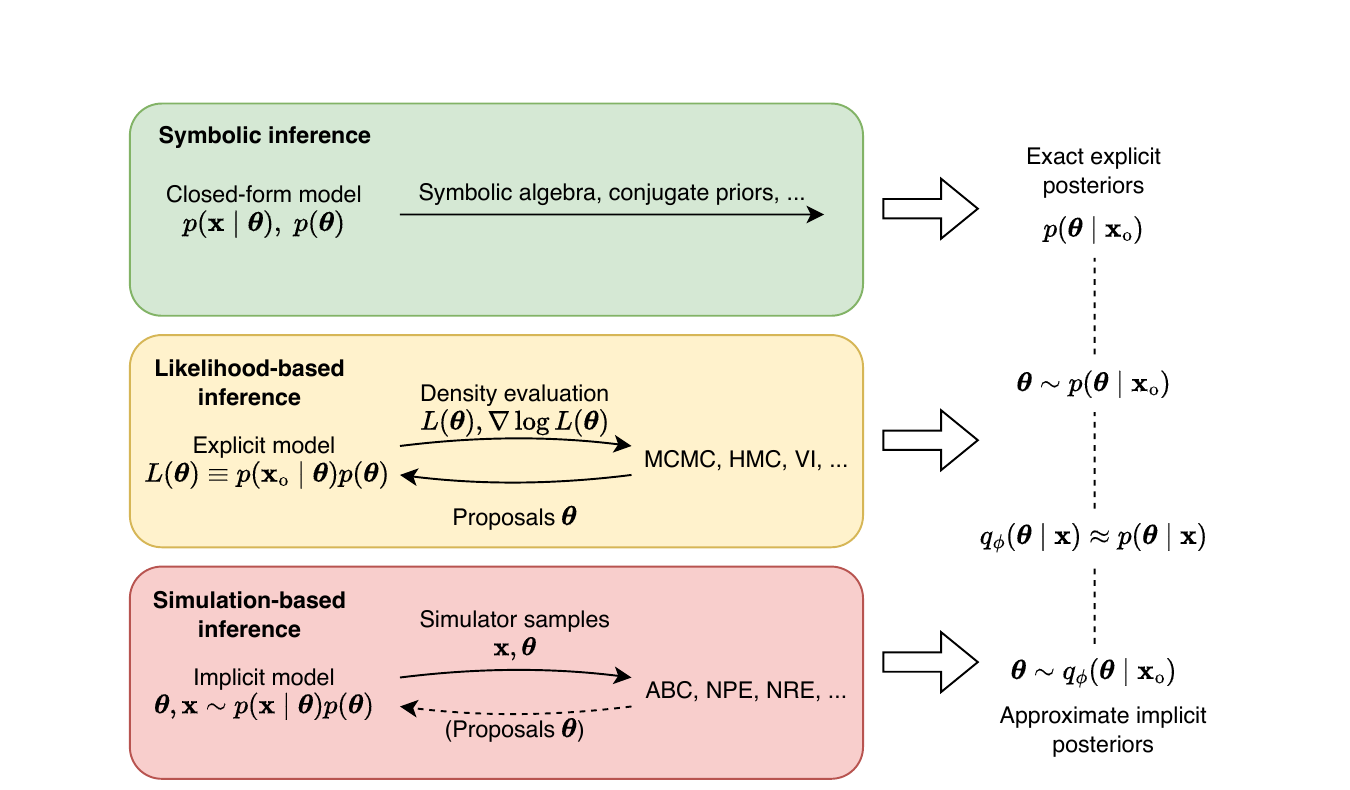

In [4]:
iw.render_figure_card('fig_three_paradigms.png', 'Symbolic conjugate updates (Weeks 1–4), explicit likelihood evaluation via MCMC/HMC (Weeks 5–9), and implicit simulation-based inference (Week 10).', max_width_px=720)

3 min | Emphasize the crucial distinction: having code that samples x ~ p(x|theta) is NOT the same as having a formula for the scalar density p(x_obs|theta).

## A Short History of Inverse Probability and Simulation

- **1763–1812 (Bayes & Laplace):** Inverse probability for tractable analytical likelihoods.
- **1940s (Ulam & von Neumann):** Monte Carlo forward simulation of complex stochastic branching processes.
- **1984–2002 (Rubin, Tavaré, Pritchard, Beaumont):** Approximate Bayesian Computation (ABC) arises in population genetics where coalescent genealogies make $p(x\mid\theta)$ intractable.
- **2016–Present (Papamakarios, Murray, Cranmer, Hermans et al.):** Neural density and ratio estimation turn simulation banks into reusable amortised Bayesian inference engines.

> **Central point:** A model that can predict experimental outcomes does *not* automatically supply an efficiently evaluable probability density for those outcomes.

2 min | Keep brisk: highlight the 70-year gap between forward Monte Carlo (1940s) and scalable neural inverse inference (2010s).

## Our Scientific Experiment: The Mystery Galton Board

A ball drops through $R = 12$ rows of pegs, bouncing left or right until landing in one of $13$ bins. Dropping $N = 100$ balls yields an observed landing histogram $x = (n_0, n_1, \dots, n_{12})$ with $\sum_{k=0}^{12} n_k = 100$.

**Question:** *Can we determine how the hidden machine is configured by observing only where the 100 balls land?*

In [5]:
iw.demo('w02_plinko_sim')

<InteractiveDemo w02_plinko_sim: W02: Animated Mystery Galton Board Simulator>

3 min | Click 'Drop 1 ball' twice to show stochasticity, then sweep Bias and Centering sliders to build physical intuition before showing formulas.

## A Simple Galton Board Has a Simple Binomial Likelihood

When there is no position-dependent restoring tendency ($\kappa = 0$), every bounce is an independent Bernoulli trial with $p = \sigma(\alpha)$:

$$P(K = k \mid \alpha, \kappa = 0) = \binom{R}{k}\,p^k\,(1 - p)^{R - k}, \qquad k \in \{0, \dots, R\}$$

Increase $N$ in the slider below to watch the empirical frequencies converge to the exact Binomial distribution, then switch the dropdown to the state-dependent board ($\kappa > 0$).

In [6]:
iw.demo('w03_analytic_galton')

<InteractiveDemo w03_analytic_galton: W03: Analytic Binomial (kappa = 0) vs State-Dependent Galton Board>

2.5 min | Show N=25 vs N=2000 in Binomial mode, then toggle to State-dependent mode to show how kappa > 0 narrows the distribution below Binomial.

## State-Dependent Transitions Break the Binomial Formula

After $t$ rows with $k_t$ rightward bounces, horizontal position is $s_t = 2k_t - t$. Define the state-dependent transition law with parameters $\theta = (\alpha, \kappa)$:

$$P(\mathrm{right} \mid s_t, \alpha, \kappa) = \sigma\!\left(\alpha - \kappa\frac{s_t}{\sqrt{R}}\right), \qquad \alpha \in [-1.5, 1.5], \quad \kappa \in [0, 3]$$

- **$\alpha$ (horizontal bias):** shifts the landing distribution left or right.
- **$\kappa$ (centering tendency):** pulls displaced balls back toward the middle ($s_t = 0$), narrowing the variance.
- Once $\kappa > 0$, transition probabilities depend on the intermediate path $s_1, \dots, s_{R-1}$, breaking the closed-form Binomial formula.

2.5 min | Point out why Binomial(R, p) fails: p^k (1-p)^(R-k) assumed every path with k rights had identical probability.

In [7]:
# Inspectable forward simulator for the Mystery Galton Board (R=12, N=100)
sim_demo = plinko.simulate_trajectories(alpha=0.60, kappa=1.20, n_balls=100, n_rows=12, seed=2026)
print("Observed Mystery Histogram x_obs (13 bins):", sim_demo["histogram"].tolist())

Observed Mystery Histogram x_obs (13 bins): [0, 0, 0, 0, 0, 7, 39, 38, 14, 2, 0, 0, 0]


## Simulating One Path vs Summing Over All Latent Paths

Evaluating the likelihood requires marginalising over every compatible latent trajectory $z$:

$$p(x \mid \theta) = \sum_{z \in \mathcal{Z}} p(x, z \mid \theta), \qquad \theta = (\alpha, \kappa)$$

**Following one random path is easy; accounting for the probabilities of all compatible paths is a fundamentally harder computational task.**

*(Scientific caveat: because this discrete pedagogical board is Markovian on 13 states, it admits an exact dynamic-programming recursion—which we deliberately hold back until Slide 31 as an independent validation benchmark. In realistic simulators with continuous/non-Markovian nuisance states, the integral $\int p(x, z\mid\theta)\,dz$ is genuinely intractable.)*

In [8]:
iw.demo('w02c_paths_challenge')

<InteractiveDemo w02c_paths_challenge: Latent Path Marginalisation & Candidate Challenge>

3 min | Drag the 'Inspect target bin k' slider on the left panel to show 924 paths hitting bin 6 vs 1 path hitting bin 12.

## The Mystery Challenge

Comparing Candidate A $(0.25, 0.25)$, Candidate B $(0.55, 1.15)$, and Candidate C $(0.95, 2.45)$ in the widget above:
- Raising both $\alpha$ and $\kappa$ shifts the mean right while pulling balls back toward the centre, creating a partial **tradeoff ridge** in $(\alpha, \kappa)$.
- With only $N = 100$ balls, random realization noise means no single simulated histogram matches $x_{\mathrm{obs}}$ bin-for-bin. We need a formal likelihood-free Bayesian procedure.

2 min | Poll the audience on Candidates A, B, C using the right-hand panel of W02c, then click 'New 100-ball realization' twice to show finite-sample variability.

## A Simple Solution: Simulate and Compare (Rejection ABC)

For $i = 1, \dots, N$:
$$\theta_i \sim p(\theta), \qquad x_i \sim p(x\mid\theta_i), \qquad \text{accept } \theta_i \text{ if } d\bigl(S(x_i), S(x_{\mathrm{obs}})\bigr) < \varepsilon$$

Accepted draws follow the exact conditional distribution given acceptance:

$$p_\varepsilon(\theta\mid x_{\mathrm{obs}}) \propto p(\theta)\,\mathbb{P}\!\left[d\bigl(S(X), S(x_{\mathrm{obs}})\bigr) < \varepsilon \;\big|\; \theta\right]$$

where the acceptance probability acts as a kernel-smoothed surrogate likelihood, converging to $p(\theta\mid S(x_{\mathrm{obs}}))$ as $\varepsilon \to 0$.

2.5 min | Walk carefully through the integral: indicator function times p(x|theta) integrates to the probability of landing within epsilon of x_obs.

## Understanding ABC Geometry in One Dimension

Consider the canonical 1D nonlinear model from the original lecture:

$$\theta \sim \chi^2(k = 5), \qquad x \mid \theta \sim \mathcal{N}\!\bigl(\sqrt{\theta},\, 1\bigr)$$

- Ancestral pairs $(\theta_i, x_i)$ populate the joint distribution $p(\theta, x)$.
- Conditioning on $x = x_{\mathrm{obs}}$ is geometrically a **horizontal slice** through $p(\theta, x)$.
- Since $\mathbb{P}(X = x_{\mathrm{obs}}) = 0$ for continuous $X$, ABC replaces the zero-thickness line with a slab $|x - x_{\mathrm{obs}}| < \varepsilon$.

2 min | Set up the geometric picture of conditioning as slicing the joint distribution p(theta, x) horizontally.

## ABC as a Slice Through the Joint Distribution

Adjust $\varepsilon$, $x_{\mathrm{obs}}$, and $N$ in `W04` below. Notice that the simulation pool stays fixed while $\varepsilon$ varies: large $\varepsilon$ leaks back toward the $\chi^2(5)$ prior, whereas tiny $\varepsilon$ leaves only a handful of noisy samples.

In [9]:
iw.demo('w04_abc_1d')

<InteractiveDemo w04_abc_1d: W04: Original 1D Chi-Squared / Normal Joint-Slice ABC Explorer>

3 min | Drag epsilon from 1.80 down to 0.06 live: show prior leakage at 1.80, sweet spot near 0.30, and severe Monte Carlo sparsity at 0.06.

## The Tolerance Problem: Audience Question

**Question:** Suppose we run Rejection ABC with a fixed budget of $N = 5{,}000$ simulations and set a tiny tolerance $\varepsilon = 10^{-4}$ so bias is negligible. Will this guarantee a highly accurate posterior estimate?

- **A.** Yes: $p_\varepsilon(\theta\mid x_{\mathrm{obs}}) \to p(\theta\mid x_{\mathrm{obs}})$ monotonically as $\varepsilon \to 0$.
- **B.** No: almost zero simulations will be accepted, so Monte Carlo variance explodes.
- **C.** Only if $\theta$ is one-dimensional.
- **D.** Both Monte Carlo starvation (few/no accepted draws) *and* potential summary-statistic information loss limit accuracy.

<details>
<summary><strong>Click to reveal answer &amp; three-part error decomposition</strong></summary>

**Answer: D (with B as the immediate finite-$N$ failure).**

1. **Finite-tolerance bias ($\varepsilon > 0$):** smooths the posterior toward the prior ($\mathcal{O}(\varepsilon^2)$).
2. **Monte Carlo variance ($M_{\mathrm{acc}} \ll N$):** at $\varepsilon = 10^{-4}$, $M_{\mathrm{acc}} \approx 0$, causing estimator variance $\propto 1/M_{\mathrm{acc}}$ to blow up.
3. **Insufficient summary bias ($S(x)$ lossy):** even at $N = \infty$ and $\varepsilon \to 0$, ABC converges to $p(\theta\mid S(x_{\mathrm{obs}}))$, never recovering discarded information.
</details>

2.5 min | Have students vote A/B/C/D before clicking Reveal. Stress the 3-way error decomposition.

## ABC and Correlated Variables

For jointly Gaussian $(\theta, x)$ with correlation $\rho$:

$$\mathbb{E}[\theta \mid x] = \mu_\theta + \rho\frac{\sigma_\theta}{\sigma_x}(x - \mu_x), \qquad \operatorname{Var}(\theta \mid x) = \sigma_\theta^2(1 - \rho^2)$$

Explore how correlation $\rho$ concentrates the posterior and how wide tolerance $\varepsilon_2$ both inflates posterior variance and biases the posterior mean toward $\mu_\theta$.

In [10]:
iw.demo('w05_corr_gauss')

<InteractiveDemo w05_corr_gauss: W05: Correlated Bivariate Gaussian ABC Tolerance Explorer>

2.5 min | Highlight the factor of rho in the conditional mean and (1 - rho^2) in the conditional variance; sweep rho from 0 to 0.9.

## Rejection ABC Solves Our Mystery Galton Board

Applying Rejection ABC to our cached Galton-Board prior-predictive bank:
- Each point in the right panel is a simulated machine $(\alpha_i, \kappa_i)$.
- Accepted machines (orange) cluster along the correlated $(\alpha, \kappa)$ region that reproduces both the location and width of $x_{\mathrm{obs}}$!

In [11]:
iw.demo('w06_plinko_abc')

<InteractiveDemo w06_plinko_abc: W06: Rejection ABC on the Mystery Galton Board>

3 min | Sweep epsilon on W06, switch between Wasserstein and Total Variation distances, and briefly toggle 'Show exact reference' to show ABC captures the right region but is noisy at small epsilon.

In [12]:
# Rejection ABC on the cached 50,000-simulation Galton-Board bank (no re-simulation!)
abc_demo = abc.run_plinko_abc(
    bundle["abc_bank"],
    bundle["primary_obs"]["x_obs"],
    epsilon=0.35,
    distance_kind="wasserstein",
    summary_kind="full_hist",
)
print(
    f"Accepted {abc_demo['n_accepted']} / {abc_demo['n_total']} "
    f"({100 * abc_demo['acceptance_rate']:.2f}%) | "
    f"ABC posterior mean (alpha, kappa) = {abc_demo['accepted_thetas'].mean(axis=0).round(3)}"
)

Accepted 9598 / 50000 (19.20%) | ABC posterior mean (alpha, kappa) = [0.732 1.934]


## Choosing Summary Statistics and Distances on the Galton Board

Compare three summaries on the same observation $x_{\mathrm{obs}}$:
1. **Mean landing position $\bar{k}$ only:** 1 summary cannot constrain 2 parameters $(\alpha, \kappa)$! Even at tiny tolerance, $\kappa$ spans nearly the entire prior $[0, 3]$.
2. **Mean and variance $(\bar{k}, s^2)$:** $\bar{k}$ constrains horizontal bias $\alpha$ while $s^2$ constrains restoring strength $\kappa$, recovering almost the full-histogram posterior!
3. **Full 13-bin histogram:** avoids summary loss, but in higher-dimensional data spaces raw vector distances suffer the $\varepsilon^D$ acceptance cliff.

In [13]:
iw.demo('w07_plinko_summaries')

<InteractiveDemo w07_plinko_summaries: W07: Summary-Statistic Sufficiency vs Information Loss on Galton Board>

3 min | Start on '1. Mean bin only' and lower M to 25 to prove shrinking epsilon NEVER recovers discarded variance info; then switch to '2. Mean & variance'.

## Why Rejection ABC Is Not Always Enough

- **Curse of dimensionality:** acceptance probability scales as $\varepsilon^{\dim S(x)}$.
- **Wasted simulations:** discarding $99\%$ of simulator runs throws away global smooth structure across $(\theta, x)$-space.
- **Hand-crafted summaries:** rarely sufficient on high-dimensional scientific observables.

> *We simulated thousands of experiments and discarded most of them. What if we could learn a smooth probability distribution from **all** of them instead?*

2 min | Use the closing question to motivate parametric density estimation in Slide 18.

## From Simulation Samples to Density Estimation

Suppose we observe samples $x_1, \dots, x_N \sim p(x)$ from an implicit distribution $p(x)$ whose density cannot be evaluated. We introduce a tractable, normalised parametric family $q_\phi(x)$ ($\int q_\phi(x)\,dx = 1$) whose log-density $\log q_\phi(x)$ and gradients $\nabla_\phi \log q_\phi(x)$ are analytically computable.

2 min | Keep p(x) (implicit truth) and q_phi(x) (normalised tractable model) visually distinct.

## Measuring Distribution Discrepancy: KL Divergence

$$D_{\mathrm{KL}}(p \,\|\, q_\phi) = \int p(x)\,\log\frac{p(x)}{q_\phi(x)}\,dx = \mathbb{E}_{p(x)}\!\bigl[\log p(x) - \log q_\phi(x)\bigr]$$

- **Non-negativity:** $D_{\mathrm{KL}}(p \,\|\, q_\phi) \ge 0$, with $D_{\mathrm{KL}}(p \,\|\, q_\phi) = 0 \iff p = q_\phi$ a.e.
- **Asymmetry (mass-covering):** wherever $p(x) > 0$ and $q_\phi(x) \to 0$, the integrand blows up to $+\infty$, forcing $q_\phi$ to cover all support of $p$.
- **Mutual information:** $I(\Theta; X) = D_{\mathrm{KL}}\bigl(p(\theta, x) \,\|\, p(\theta)p(x)\bigr)$ quantifies how much $X$ informs $\Theta$.

2.5 min | Emphasize why forward KL's mass-covering property is ideal for conservative scientific credible regions.

## From Forward KL Divergence to Maximum Likelihood

$$D_{\mathrm{KL}}(p \,\|\, q_\phi) = \mathbb{E}_{p(x)}\!\bigl[-\log q_\phi(x)\bigr] + \underbrace{\mathbb{E}_{p(x)}\!\bigl[\log p(x)\bigr]}_{\text{independent of }\phi}$$

Dropping the $\phi$-independent constant and replacing the expectation over $p(x)$ by the sample average over $x_1,\dots,x_N \sim p(x)$:

$$\phi^\star = \arg\min_\phi \mathbb{E}_{p(x)}\!\bigl[-\log q_\phi(x)\bigr] \qquad\Longrightarrow\qquad \mathcal{L}(\phi) = -\frac{1}{N}\sum_{i=1}^N \log q_\phi(x_i)$$

> **Core result:** Training a parametric density estimator by maximum likelihood requires *samples* from $p$, never density evaluations of $p$!

3 min | Pause on this derivation: every single neural density estimator in SBI (NPE and NLE) rests on these three equations.

## Gaussian Mixture Models: Building Flexible Densities

$$q_\phi(x) = \sum_{c=1}^K \pi_c\,\mathcal{N}(x;\, \mu_c, \sigma_c^2), \qquad \pi_c = \frac{e^{\eta_c}}{\sum_{j=1}^K e^{\eta_j}}, \quad \sigma_c = \exp(s_c) > 0$$

Adjust the component weights, means, and scales below to construct skewed and multimodal densities.

In [14]:
iw.demo('w08_gmm_editor')

<InteractiveDemo w08_gmm_editor: W08: Interactive 1D Gaussian Mixture Model Editor>

2.5 min | Move mu_1 and mu_2 apart to create bimodality, then push them closer with unequal weights to create skewness.

## Learning a Non-Gaussian Density from Samples

Fitting a $K$-component GMM to $x_i \sim \mathrm{Gamma}(\text{shape}=3, \text{scale}=\frac{1}{3})$ by minimising empirical NLL. Compare $K = 1$ (underfits skewness) against $K = 5$, and $N = 150$ (finite-sample noise) against $N = 4000$.

In [15]:
iw.demo('w09_gmm_gamma')

<InteractiveDemo w09_gmm_gamma: W09: Learning Gamma(3, 1/3) from Samples via Maximum Likelihood>

3 min | Drag Checkpoint from iter 0 to iter 160, then switch K=1 vs K=5 and N=150 vs N=4000.

## What Does a Machine-Learning Loss Actually Learn?

On the skewed conditional law $y \mid x \sim \mathrm{LogNormal}(s = \gamma x, \mathrm{loc} = 2x)$:
- **$L_2$ loss** learns only the conditional mean $\mathbb{E}[Y\mid x]$ (pulled upward by the heavy upper tail).
- **$L_1$ loss** learns only the conditional median $\mathrm{median}(Y\mid x)$.
- **Conditional NLL** learns the entire skewed conditional probability distribution $q_\phi(y\mid x) \approx p(y\mid x)$.

In [16]:
iw.demo('w10_loss_regression')

<InteractiveDemo w10_loss_regression: W10: L2 Mean vs L1 Median vs Conditional Density (MDN)>

3 min | Drag Slice x from 0.2 to 1.4 and switch skewness gamma to 1.25 to make the separation of mean, median, and mode visually unmistakable.

## Conditional Neural Density Estimation

Two primary architectures map conditioning inputs $x$ to normalised conditional distributions $q_\phi(y\mid x)$:
1. **Mixture Density Networks (MDNs):** neural network outputs mixture logits, means, and Cholesky factors $\{\pi_c(x), \mu_c(x), L_c(x)\}_{c=1}^K$.
2. **Conditional Normalising Flows:** compose invertible $x$-conditioned transformations $y = f_\phi(z; x)$ on $z \sim \mathcal{N}(0, I)$ with exact change-of-variables density $q_\phi(y\mid x) = p_Z(f_\phi^{-1}(y; x))\left|\det \frac{\partial f_\phi^{-1}}{\partial y}\right|$.

In [17]:
iw.demo('w10b_flow_1d')

<InteractiveDemo w10b_flow_1d: Conditional Normalising Flow Change-of-Variables Intuition>

2.5 min | Sweep Warp A(x) from 0 to 0.85 to show how a Gaussian morphs smoothly into a bimodal density, and past 1.0 to show why invertibility matters.

## Turning Simulations into Reusable Amortized Inference

Generate a prior-predictive training dataset once:

$$\mathcal{D} = \bigl\{(\theta_i, x_i)\bigr\}_{i=1}^N, \qquad \theta_i = (\alpha_i, \kappa_i) \sim p(\theta), \quad x_i \sim p(x\mid\theta_i)$$

- **Amortized inference:** upfront simulation and neural training cost is reused across arbitrarily many future datasets $x_{\mathrm{obs}}$ (critical for survey catalogues, real-time gravitational-wave triggers, and 200-run calibration checks!).
- **Sequential SBI:** steers proposal rounds toward one specific $x_{\mathrm{obs}}$ when each simulation costs hours.

In [18]:
iw.demo('w11_amortized')

<InteractiveDemo w11_amortized: W11: Amortized Simulation-to-Inference Pipeline on Galton Boards>

2.5 min | Switch across Experiments 1, 2, 3, and 4 in W11 to show zero-latency posterior evaluation without running a single new Galton-board simulation.

## Neural Posterior Estimation (NPE)

NPE trains a conditional density estimator $q_\phi(\theta\mid x) \approx p(\theta\mid x)$ directly on joint draws $(\theta_i, x_i) \sim p(\theta)p(x\mid\theta)$:

$$\mathcal{L}_{\mathrm{NPE}}(\phi) = -\frac{1}{N}\sum_{i=1}^N \log q_\phi(\theta_i \mid x_i)$$

For bounded priors $(\alpha, \kappa) \in [-1.5, 1.5]\times[0, 3]$, transforming via logit $u = g(\theta)$ with exact Jacobian $\log|\det \partial g/\partial\theta|$ guarantees $100\%$ of posterior samples lie strictly inside the physical prior box.

- **Why choose NPE:** fastest possible inference at test time (direct i.i.d. posterior draws in milliseconds, no MCMC!) and natural end-to-end compression of high-dimensional $x$.
- **Limitation:** amortised for the fixed training prior $p(\theta)$.

3 min | Highlight both the logit-support Jacobian (a common practical pitfall!) and the core strength/weakness of NPE.

## NPE Applied to the Mystery Galton Board

Explore the learned 2D joint posterior $q_\phi(\alpha, \kappa \mid x_{\mathrm{obs}})$, ancestral posterior samples, and 1D marginals across all four Galton-board experiments.

In [19]:
iw.demo('w12a_npe_plinko')

<InteractiveDemo w12a_npe_plinko: W12 (NPE): Neural Posterior Estimation on the Galton Board>

2.5 min | Point out the positive correlation tilt between alpha and kappa captured cleanly by the full-covariance Cholesky mixture components.

## Neural Likelihood Estimation (NLE)

NLE learns a normalised surrogate likelihood $q_\psi(x\mid\theta) \approx p(x\mid\theta)$, then obtains the posterior via MCMC/HMC or grid normalisation on $q_\psi(x_{\mathrm{obs}}\mid\theta)p(\theta)$.

On the Galton board, predicting softmax landing probabilities $\hat{\pi}_\psi(0\mid\theta),\dots,\hat{\pi}_\psi(R\mid\theta)$ inside the known Multinomial count law gives a **structured neural likelihood estimator**:

$$\log q_\psi(x\mid\theta) = \log N! - \sum_{k=0}^R \log(n_k!) + \sum_{k=0}^R n_k \log \hat{\pi}_\psi(k\mid\theta)$$

**Switch the prior dropdown below** to see NLE adapt to a new prior $p'(\alpha, \kappa)$ instantaneously without retraining!

In [20]:
iw.demo('w12b_nle_prior')

<InteractiveDemo w12b_nle_prior: W12 (NLE): Structured Surrogate Likelihood & Live Prior Swapping>

3.5 min | Switch the Prior dropdown from Uniform to 'Gaussian calibration prior on alpha' and drag mu_alpha to show live why NLE beats NPE whenever priors vary across downstream studies!

## Neural Ratio Estimation (NRE)

Construct balanced training pairs:
- **Class $y = 1$ (joint):** $(\theta_i, x_i) \sim p(\theta, x) = p(\theta)p(x\mid\theta)$.
- **Class $y = 0$ (independent marginal product):** $(\theta_i, x_{\pi(i)}) \sim p(\theta)p(x)$.

Minimising binary cross-entropy yields Bayes-optimal probability $D^\star(\theta, x) = \frac{p(\theta,x)}{p(\theta,x) + p(\theta)p(x)}$, so the classifier logit $f^\star(\theta, x) = \log\frac{D^\star}{1-D^\star}$ directly estimates the log likelihood-to-evidence ratio:

$$\frac{D^\star(\theta, x)}{1 - D^\star(\theta, x)} = \frac{p(\theta, x)}{p(\theta)p(x)} = \frac{p(x\mid\theta)}{p(x)} = r(\theta, x) \qquad\Longrightarrow\qquad p(\theta\mid x_{\mathrm{obs}}) = p(\theta)\,r(\theta, x_{\mathrm{obs}})$$

In [21]:
iw.demo('w13_nre_classifier')

<InteractiveDemo w13_nre_classifier: W13: Neural Ratio Estimation via Joint-vs-Marginal Classification>

3.5 min | Walk through the 2-line algebra of D*/(1-D*) carefully, then drag Probe alpha and Probe kappa on W13 to watch D_omega and r_omega respond live.

## ABC, NPE, NLE, and NRE: Why Choose Which Method?

| Method | Learned Target | Test-Time Sampling | Swap Prior $p'(\theta)$? | Combine $M$ i.i.d. Datasets? | Primary Strength |
|---|---|---|---|---|---|
| **ABC** | None | Distance filter | Reweight/rerun | Via summary | Zero neural training; transparent baseline in $\le 3$D |
| **NPE** | $q_\phi(\theta\mid x)$ | **Direct i.i.d. ($\sim\mathrm{ms}$)** | Tied to $p(\theta)$ | Requires set net | Instant amortised sampling; no MCMC at test time |
| **NLE** | $q_\psi(x\mid\theta)$ | MCMC / HMC | **Yes** | **Yes ($\prod_m q_\psi$)** | Exact prior independence + structured data likelihoods |
| **NRE** | $r_\omega(\theta,x)=\frac{p(x\mid\theta)}{p(x)}$ | MCMC / Grid | **Yes** | **Yes ($\prod_m r_\omega$)** | Unconstrained classifier on high-$D$ $x$ + prior flexibility |

Toggle any subset of **NPE**, **NLE**, **NRE**, **ABC**, and **Exact** on the shared Mystery Galton Board below:

In [22]:
iw.demo('w12_unified_compare')

<InteractiveDemo w12_unified_compare: W12: Unified Galton-Board Comparison (ABC vs NPE vs NLE vs NRE vs Exact)>

4 min | Key synthesis slide! Walk through when to pick NPE vs NLE vs NRE in real scientific workflows, then toggle contours on W12.

In [23]:
# Quantitative comparison of NPE, NLE, and NRE against the Exact DP benchmark on x_obs
ref_grid = bundle["obs_posteriors"][0]["exact"]
for method_name in ("NPE", "NLE", "NRE"):
    comp = validation.compare_posterior_grids(ref_grid, bundle["obs_posteriors"][0][method_name])
    print(
        f"{method_name}: E[alpha|x]={comp['mean_alpha']:.3f}±{comp['std_alpha']:.3f}, "
        f"E[kappa|x]={comp['mean_kappa']:.3f}±{comp['std_kappa']:.3f} | "
        f"TV={comp['tv_distance']:.3f}, KL={comp['kl_divergence']:.3f}"
    )

NPE: E[alpha|x]=0.530±0.095, E[kappa|x]=1.252±0.216 | TV=0.049, KL=0.012
NLE: E[alpha|x]=0.527±0.095, E[kappa|x]=1.243±0.204 | TV=0.007, KL=0.000
NRE: E[alpha|x]=0.532±0.093, E[kappa|x]=1.245±0.211 | TV=0.047, KL=0.008


## Did We Recover the Mystery Galton Board Settings?

- **Hidden truth revealed:** $\alpha_{\mathrm{true}} = 0.60$, $\kappa_{\mathrm{true}} = 1.20$.
- **Exact dynamic-programming benchmark:** propagating $\pi_{t+1}(k) = \pi_t(k)[1 - p_R(t,k;\theta)] + \pi_t(k-1)p_R(t,k-1;\theta)$ from $\pi_0(0)=1$ yields exact Multinomial likelihoods for independent validation.
- **Crucial statistical distinction:** $\theta_{\mathrm{true}}$ lies well inside the $68\%$ credible region, *not* at the exact posterior mode—because $N = 100$ balls carry irreducible multinomial sampling uncertainty! An inference algorithm's job is to match $p(\theta\mid x_{\mathrm{obs}})$, never to magically guess $\theta_{\mathrm{true}}$ without uncertainty.

2.5 min | Emphasize that in real SBI we do NOT have a dynamic-programming oracle—which motivates Slides 32 and 33!

In [24]:
# Exact dynamic-programming validation check: kappa=0 matches Binomial(R, sigma(alpha))
p_dp = plinko.exact_bin_probabilities(alpha=0.5, kappa=0.0, n_rows=12)
p_bin = plinko.binomial_bin_probabilities(p_right=1.0 / (1.0 + np.exp(-0.5)), n_rows=12)
print("Max |DP(kappa=0) - Binomial|:", f"{np.max(np.abs(p_dp - p_bin)):.2e}")

Max |DP(kappa=0) - Binomial|: 3.05e-16


## Posterior Predictive Checks (PPC)

Sample $\theta^{(s)} \sim q(\theta\mid x_{\mathrm{obs}})$, forward-simulate replicated 100-ball histograms $\tilde{x}^{(s)} \sim p(x\mid\theta^{(s)})$, and compare discrepancy statistics $T(\tilde{x}^{(s)})$ against $T(x_{\mathrm{obs}})$.

- **Parameter recovery** asks where $\theta$ sits *assuming the simulator family is right*.
- **Posterior predictive checks** detect **simulator misspecification** (check the *Corrupt $x_{\mathrm{obs}}$* box below!).

In [25]:
iw.demo('w14_ppc')

<InteractiveDemo w14_ppc: W14: Galton-Board Posterior Predictive Checks (PPC)>

2.5 min | Toggle 'Corrupt x_obs (sticky-peg misspecification)' to show how PPC immediately flags a broken simulator!

## Coverage and Simulation-Based Calibration

Across $J = 200$ strictly independent validation experiments $(\theta^\star_j, x_j) \sim p(\theta)p(x\mid\theta)$:
1. **Empirical HPD Coverage:** a calibrated $(1-\alpha)$ credible region must contain $\theta^\star_j$ in $(1-\alpha)$ of experiments (diagonal line).
2. **Simulation-Based Calibration (SBC):** 1D marginal PIT / rank statistics $u_j = Q_\phi(\theta^\star_j \mid x_j)$ must be $\mathcal{U}(0, 1)$ ($\cup$-shape = overconfident; $\cap$-shape = conservative/overdispersed, as seen in finite-$\varepsilon$ ABC!).

In [26]:
iw.demo('w15_coverage')

<InteractiveDemo w15_coverage: W15: Galton-Board Empirical Coverage & Simulation-Based Calibration>

3 min | Show NPE/NLE/NRE hugging the diagonal while fixed-epsilon ABC sits above the diagonal (conservative), then switch to 'Synthetic miscalibration explorer' to show U-shaped overconfidence.

## What Did We Learn? Conclusions and References

1. **Answer to our opening question:** A faithful forward simulator defines $p(\theta, x) = p(\theta)p(x\mid\theta)$ through samples, supporting full Bayesian parameter inference without explicit likelihood evaluations.
2. **ABC $\to$ Neural Density Estimation:** Minimising empirical NLL minimises forward KL divergence, utilizing *all* simulations rather than discarding $99\%$.
3. **NPE, NLE, NRE:** Choose **NPE** for millisecond amortised posterior sampling, **NLE** for structured likelihoods and changing priors, and **NRE** for classifier-based ratio inference on high-dimensional data with prior flexibility.
4. **Validation is non-negotiable:** Combine Posterior Predictive Checks (model adequacy) with empirical coverage and SBC (statistical calibration).

**Foundational Literature:**
- Tavaré et al. (1997), *Genetics* 145; Pritchard et al. (1999), *Mol. Biol. Evol.* 16; Beaumont et al. (2002), *Genetics* 162; Sisson, Fan & Beaumont (2018), *Handbook of ABC*.
- Papamakarios & Murray (2016), NeurIPS; Papamakarios et al. (2019), AISTATS; Hermans, Begy & Louppe (2020), ICML.
- Cranmer, Brehmer & Louppe (2020), *The Frontier of Simulation-Based Inference*, *PNAS* 117(48).
- Talts et al. (2018), *Validating Bayesian Inference Algorithms with SBC*, arXiv:1804.06788; Dax et al. (2021), *Phys. Rev. Lett.* 127.


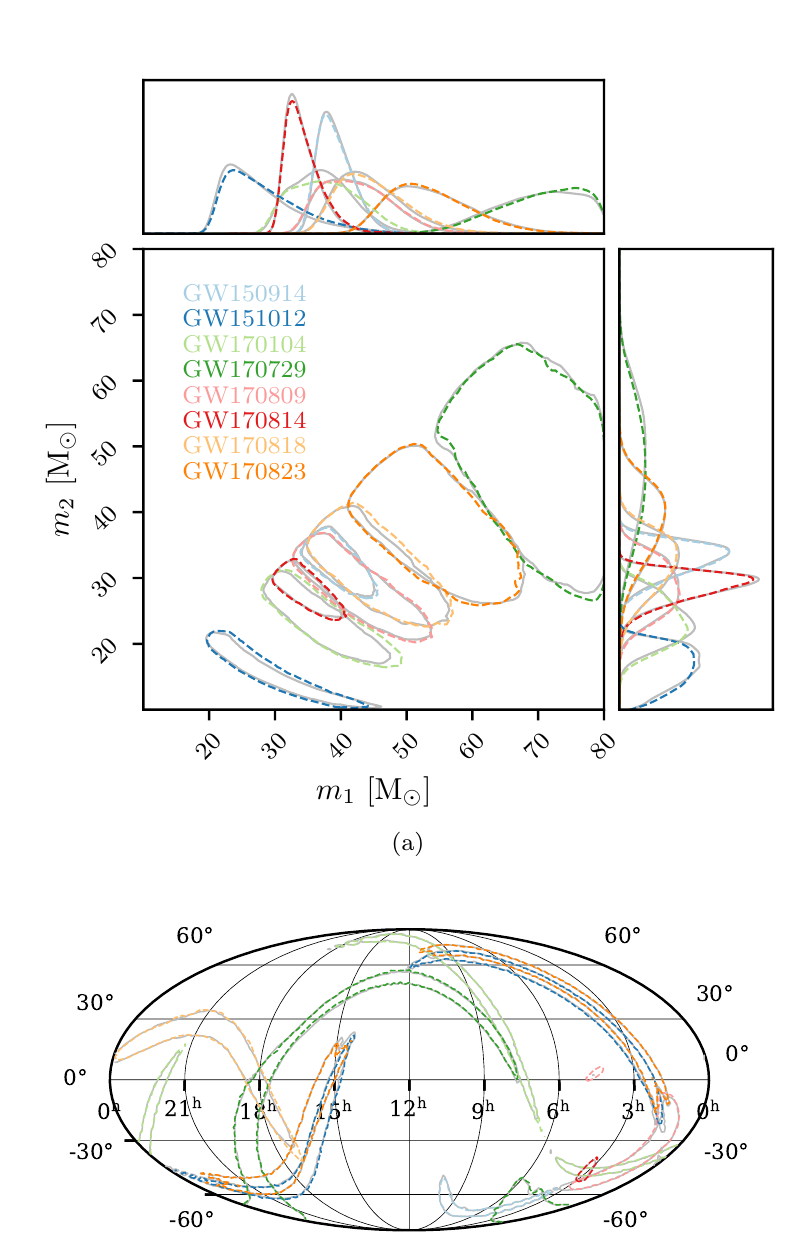

In [27]:
iw.render_figure_card('dingo_fig3.png', 'DINGO (Dax et al. 2021): conditional normalising-flow NPE inferring all 15 binary black hole merger parameters for GW150914 in seconds.', max_width_px=430)

2.5 min | Close the loop back to Slide 1 and point to DINGO gravitational-wave inference and cosmological large-scale structure.

---
## Backup Material (Extended Derivations & Machine Learning Foundations)

## Backup B1: Conditional Bivariate Gaussian Derivation

Completing the square on standardized $\tilde{\theta} = (\theta-\mu_\theta)/\sigma_\theta$ and $\tilde{x} = (x-\mu_x)/\sigma_x$:

$$\frac{\tilde{\theta}^2 - 2\rho\tilde{\theta}\tilde{x} + \tilde{x}^2}{1-\rho^2} = \frac{(\tilde{\theta} - \rho\tilde{x})^2}{1-\rho^2} + \tilde{x}^2 \implies \theta \mid x \sim \mathcal{N}\!\left(\mu_\theta + \rho\frac{\sigma_\theta}{\sigma_x}(x - \mu_x),\; \sigma_\theta^2(1 - \rho^2)\right)$$

## Backup B2: ABC Small-Tolerance Asymptotics

Taylor-expanding $p(s\mid\theta)$ around $s_{\mathrm{obs}}$ shows $\mathbb{P}(\|S(X)-s_{\mathrm{obs}}\|<\varepsilon\mid\theta) = V_D\varepsilon^D\bigl[p(s_{\mathrm{obs}}\mid\theta) + \mathcal{O}(\varepsilon^2)\bigr]$: leading bias is $\mathcal{O}(\varepsilon^2)$ while acceptance probability drops as $\mathcal{O}(\varepsilon^D)$.

## Backup B3: Distance Metrics and Sufficiency

- **1D Wasserstein distance** $W_1(\hat{p},\hat{q}) = \sum_{k=0}^{R-1} |\hat{F}_p(k) - \hat{F}_q(k)|$ respects bin geometry (shifting mass from bin 6 to 7 costs less than 6 to 12).
- **Fisher–Neyman sufficiency:** $p(x\mid\theta) = h(x)g_\theta(S(x)) \iff p(\theta\mid x) = p(\theta\mid S(x))$ for every prior $p(\theta)$.

## Backup B4: Numerically Stable GMM Parameterisation

Using softmax logits $\eta_c$, positive Cholesky diagonals $L_{c,ii} = \mathrm{softplus}(\tilde{\ell}_{c,ii}) + \epsilon$, and `logsumexp` prevents numerical underflow in low-density tails during NLL training.

## Backup B5: Supervised Learning and Empirical Risk Minimisation

Population risk $\mathcal{R}(f) = \mathbb{E}_{p(x,y)}[\ell(y, f(x))]$ is estimated by empirical risk $\hat{\mathcal{R}}_N(\phi) = \frac{1}{N}\sum_{i=1}^N \ell(y_i, f_\phi(x_i))$. Because $\theta_i \sim p(\theta), x_i \sim p(x\mid\theta_i)$ are synthetic, fresh simulation batches prevent memorisation.

## Backup B6: Variational Proofs of $L_2$ Mean and $L_1$ Median

- **Squared loss:** $\frac{\partial}{\partial\hat{y}}\mathbb{E}[(Y-\hat{y})^2\mid x] = -2(\mathbb{E}[Y\mid x] - \hat{y}) = 0 \implies \hat{y}^\star = \mathbb{E}[Y\mid x]$.
- **Absolute loss:** Leibniz's rule gives $F_{Y\mid X}(\hat{y}^\star\mid x) - (1 - F_{Y\mid X}(\hat{y}^\star\mid x)) = 0 \implies F_{Y\mid X}(\hat{y}^\star\mid x) = \frac{1}{2}$.

## Backup B7: Neural Network Layers and Activations

Composing affine layers $h^{(\ell)} = \psi(W^{(\ell)}h^{(\ell-1)} + b^{(\ell)})$ with nonlinear activations ($\mathrm{ReLU}$, $\mathrm{SiLU}$, $\tanh$) provides a universal function approximator mapping data embeddings to distribution parameters.

## Backup B8: Gradient-Based Optimisation Live

Interactive stochastic gradient descent trainer minimising Gaussian negative log-likelihood on heteroscedastic data.

In [28]:
iw.demo('wb_mlp_sgd')

<InteractiveDemo wb_mlp_sgd: Backup B8: Live Neural Conditional Density SGD Trainer>

## Backup B9: Maximum Likelihood vs MAP and Regularisation

Adding $-\log p(\phi)$ to the empirical NLL yields MAP estimation: an isotropic Gaussian prior on weights corresponds to $L_2$ weight decay, while a Laplace prior corresponds to $L_1$ regularisation.

## Backup B10: Epistemic Network Uncertainty and Deep Ensembles

Marginalising over finite-budget weight uncertainty via deep ensembles $\bar{q}(\theta\mid x_{\mathrm{obs}}) = \frac{1}{M}\sum_{m=1}^M q_{\phi^{(m)}}(\theta\mid x_{\mathrm{obs}})$ improves calibration against overconfidence (Hermans et al. 2022).

## Backup B11: Conditional Mixture Density Network Architecture

`PlinkoNPEModel` maps 15-dimensional histogram features through a 3-layer `SiLU` encoder to $K=8$ 2D Cholesky-parameterised Gaussian components in logit-prior space.

## Backup B12: Affine-Coupling Normalising Flows Live

Four alternating RealNVP affine-coupling layers trained live in the browser via exact negative log-likelihood on a curved 2D banana distribution.

In [29]:
iw.demo('wb_flow_2d')

<InteractiveDemo wb_flow_2d: Backup B12: Live 4-Layer 2D Affine-Coupling Flow Trainer>

## Backup B13: Sequential vs Amortized SBI

Sequential rounds draw $\theta \sim \tilde{p}_r(\theta)$ near the current posterior for a single $x_{\mathrm{obs}}$. **SNLE** learns $p(x\mid\theta)$ directly on any proposal support without atomic/truncation corrections, whereas **SNPE** must adjust for $\tilde{p}_r(\theta) \neq p(\theta)$.

## Backup B14: NRE with Arbitrary Class Priors

With $K$ negative marginal draws per positive joint draw ($\pi_1/\pi_0 = 1/K$), the optimal classifier logit shifts by $-\log K$, so $\log r(\theta, x) = f^\star(\theta, x) + \log K$.

## Backup B15: Calibration Blind Spots, Misspecification, and Exercise Session

- **Calibration is necessary, not sufficient:** $q(\theta\mid x) = p(\theta)$ passes global SBC trivially! Pair SBC with TARP / Cramér–Wold projections, local stratification, and posterior shrinkage checks.
- **Model misspecification:** always audit out-of-distribution summary statistics and Posterior Predictive Checks before scientific interpretation.
- **Companion Exercise Notebook:** see `EXERCISES/week10_simulation_based_inference.ipynb` (and `exercise_solutions/week10_simulation_based_inference_solutions.ipynb`) to implement ABC, NPE, NLE, and NRE on the Mystery Galton Board.

## Backup B16: Live NPE Training on the Galton Board

Interactive epoch-by-epoch training explorer for `PlinkoNPEModel` across simulation budgets $M \in \{800, 4{,}000, 36{,}000\}$ and mixture capacities $K \in \{1, 8\}$.

In [30]:
iw.demo('wt_npe_plinko')

<InteractiveDemo wt_npe_plinko: Train NPE on the Galton Board: Conditional Posterior q_φ(α, κ | x_obs)>

## Backup B17: Live NLE Training & Prior Swapping on the Galton Board

Interactive epoch-by-epoch training explorer for `PlinkoNLEModel` showing learned 13-bin probabilities, induced posterior contours under live prior swapping, and multinomial NLL convergence.

In [31]:
iw.demo('wt_nle_plinko')

<InteractiveDemo wt_nle_plinko: Train NLE on the Galton Board: Surrogate Likelihood q_ψ(x | α, κ) & Prior Swap>

## Backup B18: Live NRE Classifier Training on the Galton Board

Interactive epoch-by-epoch training explorer for `PlinkoNREModel` comparing multi-negative ($K_{\mathrm{neg}}=24$), single-negative ($K_{\mathrm{neg}}=1$), and small-sample ($M=1{,}200$) binary classification regimes.

In [32]:
iw.demo('wt_nre_plinko')

<InteractiveDemo wt_nre_plinko: Train NRE on the Galton Board: Joint-vs-Marginal Classifier D_ω(θ, x_obs)>